# British Airways Flight Delay Analysis ? 03. Business Analysis & Scoring Models
**Project:** End-to-End Operational Analytics & BI Dashboard  
**Phase:** Root Cause Pareto Analytics, Airport & Route Scoring Models, Statistical Tests & Business Impact  
**Author:** Senior Data Analyst & Airline Operations Team  

---
### Business Analysis Objectives:
1. Conduct Delay Root Cause Analysis and identify the **80/20 Pareto drivers**.
2. Develop a multi-factor **Airport Operational Performance Score (0?100)** with performance tiers.
3. Build a **Route Risk Index** to identify critical disruption exposure across city pairs.
4. Execute advanced statistical modeling:
   - Delay propagation regression ($R^2$, slope, intercept)
   - Peak vs Off-Peak hypothesis testing ($t$-test)
   - Haul-type comparative ANOVA
5. Run analytical SQL queries on the SQLite analytics warehouse.
6. Formulate actionable, numbers-driven operational and customer experience recommendations.


In [1]:
import os
import sys
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Add src to path
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..', 'src')))
from analysis import (
    compute_overall_kpis,
    compute_pareto_root_causes,
    compute_airport_performance_score,
    compute_route_risk_score,
    compute_advanced_statistics
)
from database import execute_query, DB_PATH

plt.style.use('seaborn-v0_8-whitegrid')
print("Business analysis environment initialized.")


Business analysis environment initialized.


## 1. Load Feature-Engineered Dataset

In [2]:
features_path = os.path.join('..', 'data', 'processed', 'flight_features.csv')
if not os.path.exists(features_path):
    features_path = 'data/processed/flight_features.csv'

df = pd.read_csv(features_path)
print(f"Loaded {len(df):,} flight records for business modeling.")


Loaded 75,080 flight records for business modeling.


## 2. Delay Root Cause & Pareto 80/20 Analysis

In [3]:
pareto_df = compute_pareto_root_causes(df)
print("=== DELAY ROOT CAUSE PARETO SUMMARY ===")
pareto_df[['delay_cause', 'total_delay_minutes', 'pct_of_total_minutes', 'cumulative_pct', 'avg_delay_per_incident', 'is_top_80_pct']]


=== DELAY ROOT CAUSE PARETO SUMMARY ===


,delay_cause,total_delay_minutes,pct_of_total_minutes,cumulative_pct,avg_delay_per_incident,is_top_80_pct
0,Late-Arriving Aircraft,409875.0,38.14,38.14,17.04,True
1,Carrier / Airline Operations,310085.2,28.85,66.99,21.46,True
2,Air Traffic / NAS Flow,187948.9,17.49,84.47,36.63,True
3,Severe Weather,149016.6,13.86,98.34,36.99,False
4,Security Operations,17848.3,1.66,100.00,37.03,False


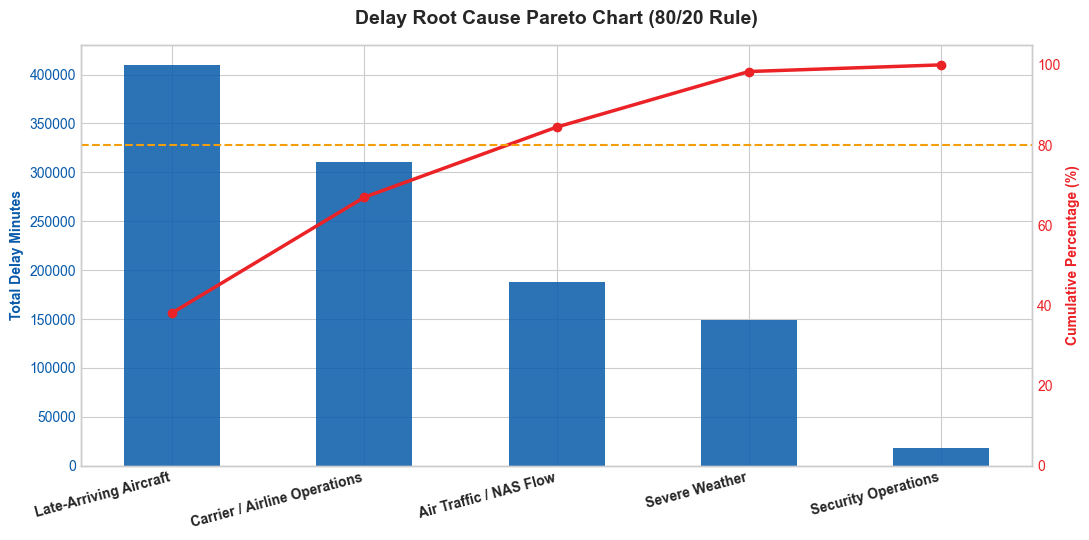

In [4]:
fig, ax1 = plt.subplots(figsize=(11, 5.5))

color = '#075AAA'
ax1.bar(pareto_df['delay_cause'], pareto_df['total_delay_minutes'], color=color, alpha=0.85, width=0.5)
ax1.set_ylabel('Total Delay Minutes', color=color, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=color)
plt.xticks(rotation=15, ha='right', fontweight='bold')

ax2 = ax1.twinx()
color = '#EB2226'
ax2.plot(pareto_df['delay_cause'], pareto_df['cumulative_pct'], color=color, marker='o', linewidth=2.5)
ax2.axhline(80, color='#F59E0B', linestyle='--', linewidth=1.5, label='80% Pareto Threshold')
ax2.set_ylabel('Cumulative Percentage (%)', color=color, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylim(0, 105)
ax2.grid(False)

plt.title('Delay Root Cause Pareto Chart (80/20 Rule)', fontweight='bold', fontsize=14, pad=15)
plt.tight_layout()
plt.show()


## 3. Airport Operational Performance Scoring (0?100)
The normalized Airport Performance Score formula evaluates:
- On-Time Performance (55% weight)
- Departure Delay Severity (30% weight)
- Cancellation Reliability (15% weight)


In [5]:
airport_scores = compute_airport_performance_score(df)
print("Top 5 Ranked Airports:")
display(airport_scores[['rank', 'airport_code', 'airport_city', 'performance_score', 'performance_tier', 'delay_rate_pct', 'on_time_performance_pct']].head(5))

print("\nBottom 5 Ranked Airports (Operational Improvement Opportunities):")
display(airport_scores[['rank', 'airport_code', 'airport_city', 'performance_score', 'performance_tier', 'delay_rate_pct', 'on_time_performance_pct']].tail(5))


Top 5 Ranked Airports:


,rank,airport_code,airport_city,performance_score,performance_tier,delay_rate_pct,on_time_performance_pct
0,1,SFO,San Francisco,69.7,Moderate,31.11,68.89
1,2,LHR,London Heathrow,67.9,Moderate,27.70,72.30
2,3,BOM,Mumbai Chhatrapati,67.4,Moderate,33.89,66.11
3,4,LCY,London City,67.2,Moderate,29.19,70.81
4,5,LGW,London Gatwick,66.8,Moderate,29.56,70.44



Bottom 5 Ranked Airports (Operational Improvement Opportunities):


,rank,airport_code,airport_city,performance_score,performance_tier,delay_rate_pct,on_time_performance_pct
37,38,GLA,Glasgow,59.3,Moderate,40.24,59.76
38,39,ATH,Athens,59.1,Moderate,42.81,57.19
39,40,NCL,Newcastle,58.4,Moderate,40.31,59.69
40,41,BFS,Belfast Intl,58.3,Moderate,40.62,59.38
41,42,CPH,Copenhagen,57.1,Moderate,42.09,57.91


## 4. Route Risk Assessment & Critical Corridor Identification

In [6]:
route_risk = compute_route_risk_score(df)
print("=== TOP 10 HIGHEST RISK FLIGHT CORRIDORS ===")
display(route_risk[['route', 'haul_type', 'distance_km', 'total_flights', 'delay_rate_pct', 'avg_arrival_delay_min', 'risk_score', 'risk_category']].head(10))

print("\nRisk Category Breakdown:")
display(route_risk['risk_category'].value_counts())


=== TOP 10 HIGHEST RISK FLIGHT CORRIDORS ===


,route,haul_type,distance_km,total_flights,delay_rate_pct,avg_arrival_delay_min,risk_score,risk_category
0,CPH -> LHR,Short-Haul,980,730,42.09,21.56,75.1,Critical
1,NCL -> LHR,Short-Haul,404,730,40.31,19.26,74.1,Critical
2,BFS -> LHR,Short-Haul,523,730,40.62,21.24,73.1,Critical
3,EDI -> LGW,Short-Haul,566,671,40.52,20.08,73.0,Critical
4,GLA -> LHR,Short-Haul,555,1187,40.66,20.19,72.5,Critical
5,FCO -> LHR,Short-Haul,1445,853,38.59,19.77,71.6,Critical
6,ATH -> LHR,Medium-Haul,2410,671,42.81,20.01,71.0,Critical
7,GLA -> LGW,Short-Haul,585,671,39.51,18.57,71.0,Critical
8,MAD -> LHR,Short-Haul,1246,853,40.84,19.90,71.0,Critical
9,EDI -> LHR,Short-Haul,534,1552,41.61,20.16,70.6,Critical



Risk Category Breakdown:


risk_category
High        78
Medium      18
Critical    10
Name: count, dtype: int64

## 5. Statistical Hypothesis Testing & Delay Propagation Modeling

In [7]:
stat_results = compute_advanced_statistics(df)
stat_df = pd.DataFrame(list(stat_results.items()), columns=['Statistical Metric', 'Result'])
stat_df


,Statistical Metric,Result
0,dep_arr_pearson_corr,9.643000e-01
1,dep_arr_pearson_pvalue,0.000000e+00
2,dep_arr_spearman_corr,8.703000e-01
3,delay_propagation_slope,9.642000e-01
4,delay_propagation_intercept,2.006300e+00
5,delay_propagation_r2,9.299000e-01
6,peak_vs_offpeak_tstat,-3.768700e+00
7,peak_vs_offpeak_pvalue,1.647071e-04
8,peak_mean_arr_delay,1.560000e+01
9,offpeak_mean_arr_delay,1.663000e+01


## 6. SQL Analytical Warehouse Queries (Live Ingestion)

In [8]:
sql_db_path = os.path.join('..', 'data', 'processed', 'flight_analytics.db')
if not os.path.exists(sql_db_path):
    sql_db_path = 'data/processed/flight_analytics.db'

sql_q1 = '''SELECT 
    f.origin_airport,
    a.city,
    COUNT(*) AS total_flights,
    ROUND(CAST(SUM(CASE WHEN f.is_cancelled = 0 AND f.delay_status = 'Delayed' THEN 1 ELSE 0 END) AS FLOAT) / 
          SUM(CASE WHEN f.is_cancelled = 0 THEN 1 ELSE 0 END) * 100, 2) AS delay_rate_pct,
    ROUND(AVG(CASE WHEN f.is_cancelled = 0 THEN f.departure_delay END), 2) AS avg_dep_delay_min
FROM flights f
JOIN airports a ON f.origin_airport = a.airport_code
GROUP BY f.origin_airport, a.city
HAVING COUNT(*) >= 100
ORDER BY delay_rate_pct DESC
LIMIT 5;'''

print('Executing SQL Query 1: Top Delayed Airports via SQLite:')
execute_query(sql_q1, db_path=sql_db_path)


Executing SQL Query 1: Top Delayed Airports via SQLite:


,origin_airport,city,total_flights,delay_rate_pct,avg_dep_delay_min
0,YYZ,Toronto Pearson,365,42.98,15.80
1,ATH,Athens,671,42.81,15.48
2,CPH,Copenhagen,730,42.09,17.31
3,LIS,Lisbon,730,41.60,16.01
4,CDG,Paris Charles de Gaulle,1552,41.30,16.04
